In [15]:
import requests
from bs4 import BeautifulSoup, NavigableString
import pandas as pd
import time
from datetime import datetime
import re

class KnocksAndBansInjuryScraper:
    def __init__(self):
        self.base_url = "https://www.knocksandbans.com"
        self.headers = {
            'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36',
        }
    
    def scrape_injuries(self):
        """Scrape injuries using a simpler approach"""
        try:
            print(f"🔄 Fetching from {self.base_url}...")
            time.sleep(2)
            
            response = requests.get(self.base_url, headers=self.headers)
            response.raise_for_status()
            
            soup = BeautifulSoup(response.content, 'html.parser')
            injuries = []
            
            # Find ALL links that match player pattern
            all_player_links = soup.find_all('a', href=re.compile(r'^/\d+-[\w-]+$'))
            
            print(f"Found {len(all_player_links)} potential player links")
            
            # Debug: show first few h2 tags
            all_h2s = soup.find_all('h2')
            print(f"Found {len(all_h2s)} h2 tags (club headers)")
            if all_h2s:
                print(f"First h2: {all_h2s[0].get_text()[:50]}")
            
            for idx, link in enumerate(all_player_links):
                try:
                    # Get player name from strong tag
                    strong = link.find('strong')
                    if not strong:
                        continue
                    
                    player_name = strong.text.strip()
                    
                    # Get the raw text
                    text = link.get_text()
                    
                    # Find club - Multiple approaches
                    club_name = "Unknown"
                    found_club = False
                    
                    # Method 1: Check href - if it goes to player page, fetch club from there later
                    # For now, look at surrounding text
                    
                    # Method 2: Look at all text in parent divs for club name mentions
                    parent = link.find_parent()
                    if parent:
                        parent_text = parent.get_text()
                        # Known club names to search for
                        known_clubs = [
                            'Arsenal', 'Aston Villa', 'Bournemouth', 'Brentford', 'Brighton', 
                            'Burnley', 'Chelsea', 'Crystal Palace', 'Everton', 'Fulham',
                            'Leeds United', 'Leicester', 'Liverpool', 'Manchester City', 
                            'Manchester United', 'Newcastle', 'Nottingham Forest', 
                            'Southampton', 'Tottenham', 'West Ham', 'Wolves', 'Sunderland'
                        ]
                        for club in known_clubs:
                            if club in parent_text and club != player_name:
                                club_name = club
                                found_club = True
                                if idx < 3:
                                    print(f"  Player {idx} ({player_name}): Found club from text: {club_name}")
                                break
                    
                    # Method 3: Club logo check
                    if not found_club and parent:
                        all_imgs = parent.find_all('img', alt=True)
                        for img in all_imgs:
                            alt_text = img.get('alt', '').strip()
                            if (alt_text != player_name and 
                                len(alt_text) > 3 and 
                                ('FC' in alt_text or 'United' in alt_text or 'City' in alt_text or 
                                 'Albion' in alt_text or 'Palace' in alt_text or 'Villa' in alt_text or
                                 'Hotspur' in alt_text or 'Wanderers' in alt_text or 'Forest' in alt_text)):
                                club_name = alt_text.replace(' logo', '').strip()
                                found_club = True
                                if idx < 3:
                                    print(f"  Player {idx} ({player_name}): Found club from logo: {club_name}")
                                break
                    
                    # Method 4: h2 headers (works for organized sections)
                    if not found_club:
                        current = link
                        for _ in range(100):
                            prev_h2 = current.find_previous('h2')
                            if not prev_h2:
                                break
                            
                            h2_text = prev_h2.get_text(strip=True)
                            
                            if 'Unavailable' in h2_text or 'injury' in h2_text.lower() or 'news' in h2_text.lower():
                                current = prev_h2
                                continue
                            
                            club_link = prev_h2.find('a')
                            if club_link:
                                club_name = club_link.text.strip()
                            else:
                                club_name = h2_text
                            
                            found_club = True
                            if idx < 3:
                                print(f"  Player {idx} ({player_name}): Found club from h2: {club_name}")
                            break
                    
                    if not found_club and idx < 3:
                        print(f"  Player {idx} ({player_name}): ✗ No club found")
                    
                    # Extract injury type - text between dash and "Status"
                    injury_type = "Unknown"
                    if ' - ' in text and 'Status' in text:
                        parts = text.split(' - ')
                        if len(parts) > 1:
                            second_part = parts[1]
                            if 'Status' in second_part:
                                injury_type = second_part.split('Status')[0].strip()
                    
                    # Extract status
                    status = "Unknown"
                    status_match = re.search(r'Status:\s*(\w+%?)', text)
                    if status_match:
                        status = status_match.group(1)
                    
                    # Extract return date
                    expected_return = "Unknown"
                    return_match = re.search(r'Est\.\s*Return\s*(\d{2}/\d{2}/\d{2})', text)
                    if return_match:
                        expected_return = return_match.group(1)
                    elif 'Unknown' in text and 'Return' in text:
                        expected_return = "Unknown"
                    
                    injuries.append({
                        'player': player_name,
                        'club': club_name,
                        'injury_type': injury_type,
                        'status': status,
                        'expected_return': expected_return,
                        'scraped_at': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
                    })
                    
                except Exception as e:
                    continue
            
            print(f"✅ Successfully parsed {len(injuries)} injuries")
            return injuries
            
        except Exception as e:
            print(f"❌ Error: {e}")
            import traceback
            traceback.print_exc()
            return None
    
    def to_dataframe(self, injuries):
        if injuries:
            return pd.DataFrame(injuries)
        return None
    
    def save_csv(self, injuries, filename='knocksandbans_injuries.csv'):
        if injuries:
            df = pd.DataFrame(injuries)
            try:
                df.to_csv(filename, index=False)
                print(f"💾 Saved to {filename}")
            except:
                print(f"⚠️  Could not save (read-only)")
            return df
        return None


# RUN
if __name__ == "__main__":
    print("🏥 KNOCKSANDBANS SCRAPER\n")
    
    scraper = KnocksAndBansInjuryScraper()
    injuries = scraper.scrape_injuries()
    
    if injuries and len(injuries) > 0:
        df = scraper.to_dataframe(injuries)
        
        print("\n" + "="*80)
        print("RESULTS")
        print("="*80)
        print(f"Total: {len(df)} injuries")
        print(f"Clubs: {df['club'].nunique()}")
        
        print("\nTop 5 clubs:")
        print(df['club'].value_counts().head())
        
        print("\nFirst 20 injuries:")
        print(df[['player', 'club', 'injury_type', 'status', 'expected_return']].head(20))
        
        print(f"\n💡 To see ALL {len(df)} injuries:")
        print("   Type: df")
        print("   Or: print(df.to_string())")
        print("   Or save to file in a writable location")
        
        # Try to save with full path options
        import os
        save_paths = [
            'knocksandbans_injuries.csv',
            os.path.expanduser('~/knocksandbans_injuries.csv'),
            os.path.expanduser('~/Desktop/knocksandbans_injuries.csv'),
            os.path.expanduser('~/Downloads/knocksandbans_injuries.csv'),
        ]
        
        saved = False
        for path in save_paths:
            try:
                df.to_csv(path, index=False)
                print(f"\n✅ Successfully saved to: {path}")
                saved = True
                break
            except:
                continue
        
        if not saved:
            print("\n⚠️  Could not save to disk. DataFrame available as 'df'")
        
    else:
        print("\n❌ No injuries found - the page structure may have changed")
        print("Try visiting https://www.knocksandbans.com in your browser")

🏥 KNOCKSANDBANS SCRAPER

🔄 Fetching from https://www.knocksandbans.com...
Found 124 potential player links
Found 48 h2 tags (club headers)
First h2:  Latest injury news
  Player 0 (Jamie Gittens): ✗ No club found
  Player 1 (Matz Sels): Found club from logo: Nottingham Forest
  Player 2 (Pedro Neto): ✗ No club found
✅ Successfully parsed 114 injuries

RESULTS
Total: 114 injuries
Clubs: 25

Top 5 clubs:
club
Tottenham            10
Chelsea               9
Bournemouth           8
Newcastle             7
Nottingham Forest     7
Name: count, dtype: int64

First 20 injuries:
             player                    club           injury_type status   
0     Jamie Gittens                 Unknown             hamstring    OUT  \
1         Matz Sels       Nottingham Forest                 groin    50%   
2        Pedro Neto                 Unknown           undisclosed    50%   
3       Anton Stach            Leeds United                 groin    OUT   
4       Lewis Miley        Newcastle United

In [16]:
df

,player,club,injury_type,status,expected_return,scraped_at
0,Jamie Gittens,Unknown,hamstring,OUT,21/03/26,2026-02-09 14:37:41
1,Matz Sels,Nottingham Forest,groin,50%,06/02/26,2026-02-09 14:37:41
2,Pedro Neto,Unknown,undisclosed,50%,07/02/26,2026-02-09 14:37:41
3,Anton Stach,Leeds United,groin,OUT,15/02/26,2026-02-09 14:37:41
4,Lewis Miley,Newcastle United,knee,50%,07/02/26,2026-02-09 14:37:41
...,...,...,...,...,...,...
109,Jamie Gittens,Recent,Unknown,Unknown,Unknown,2026-02-09 14:37:41
110,Matz Sels,Recent,Unknown,Unknown,Unknown,2026-02-09 14:37:41
111,Pedro Neto,Recent,Unknown,Unknown,Unknown,2026-02-09 14:37:41
112,Anton Stach,Recent,Unknown,Unknown,Unknown,2026-02-09 14:37:41


In [17]:
display(df)

,player,club,injury_type,status,expected_return,scraped_at
0,Jamie Gittens,Unknown,hamstring,OUT,21/03/26,2026-02-09 14:37:41
1,Matz Sels,Nottingham Forest,groin,50%,06/02/26,2026-02-09 14:37:41
2,Pedro Neto,Unknown,undisclosed,50%,07/02/26,2026-02-09 14:37:41
3,Anton Stach,Leeds United,groin,OUT,15/02/26,2026-02-09 14:37:41
4,Lewis Miley,Newcastle United,knee,50%,07/02/26,2026-02-09 14:37:41
...,...,...,...,...,...,...
109,Jamie Gittens,Recent,Unknown,Unknown,Unknown,2026-02-09 14:37:41
110,Matz Sels,Recent,Unknown,Unknown,Unknown,2026-02-09 14:37:41
111,Pedro Neto,Recent,Unknown,Unknown,Unknown,2026-02-09 14:37:41
112,Anton Stach,Recent,Unknown,Unknown,Unknown,2026-02-09 14:37:41


In [19]:
# Save to Desktop
df.to_csv('/Users/ethanbensadoun/Desktop/injuries.csv', index=False)

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming df is already loaded from the scraper
print("="*80)
print("PREMIER LEAGUE INJURY DATA - EDA")
print("="*80)

# 1. Basic Overview
print("\n📊 DATASET OVERVIEW")
print(f"Total injuries: {len(df)}")
print(f"Unique players: {df['player'].nunique()}")
print(f"Unique clubs: {df['club'].nunique()}")
print(f"Date scraped: {df['scraped_at'].iloc[0]}")

# 2. Club Analysis
print("\n🏥 TOP 10 CLUBS BY INJURY COUNT")
print(df['club'].value_counts().head(10))

# 3. Injury Type Breakdown
print("\n🤕 MOST COMMON INJURY TYPES")
print(df['injury_type'].value_counts().head(10))

# 4. Status Distribution
print("\n📊 PLAYER STATUS BREAKDOWN")
print(df['status'].value_counts())

# 5. Return Date Analysis
print("\n📅 RETURN DATE PATTERNS")
# Convert return dates to datetime
df_temp = df[df['expected_return'] != 'Unknown'].copy()
if len(df_temp) > 0:
    df_temp['return_date'] = pd.to_datetime(df_temp['expected_return'], format='%d/%m/%y', errors='coerce')
    df_temp['days_until_return'] = (df_temp['return_date'] - pd.Timestamp.now()).dt.days
    
    print(f"Avg days until return: {df_temp['days_until_return'].mean():.1f}")
    print(f"Median days until return: {df_temp['days_until_return'].median():.1f}")
    print(f"Players returning within 7 days: {len(df_temp[df_temp['days_until_return'] <= 7])}")
    print(f"Players out > 30 days: {len(df_temp[df_temp['days_until_return'] > 30])}")

# 6. Data Quality Check
print("\n⚠️  DATA QUALITY")
print(f"Unknown clubs: {len(df[df['club'] == 'Unknown'])}")
print(f"Unknown injury types: {len(df[df['injury_type'] == 'Unknown'])}")
print(f"Unknown return dates: {len(df[df['expected_return'] == 'Unknown'])}")

# 7. Sample problematic records
if len(df[df['club'] == 'Unknown']) > 0:
    print("\n🔍 PLAYERS WITH UNKNOWN CLUBS:")
    print(df[df['club'] == 'Unknown'][['player', 'injury_type', 'status', 'expected_return']].head())

print("\n" + "="*80)

PREMIER LEAGUE INJURY DATA - EDA

📊 DATASET OVERVIEW
Total injuries: 114
Unique players: 99
Unique clubs: 25
Date scraped: 2026-02-09 14:37:41

🏥 TOP 10 CLUBS BY INJURY COUNT
club
Tottenham            10
Chelsea               9
Bournemouth           8
Newcastle             7
Nottingham Forest     7
Leeds United          6
Manchester City       6
Liverpool             6
Burnley               5
Crystal Palace        5
Name: count, dtype: int64

🤕 MOST COMMON INJURY TYPES
injury_type
knee           28
hamstring      17
ankle          13
undisclosed     9
thigh           5
groin           5
Unknown         5
suspension      4
muscle          4
calf            3
Name: count, dtype: int64

📊 PLAYER STATUS BREAKDOWN
status
OUT        81
50%        16
25%         9
Unknown     5
75%         3
Name: count, dtype: int64

📅 RETURN DATE PATTERNS
Avg days until return: 32.9
Median days until return: 11.0
Players returning within 7 days: 44
Players out > 30 days: 33

⚠️  DATA QUALITY
Unknown clubs: 

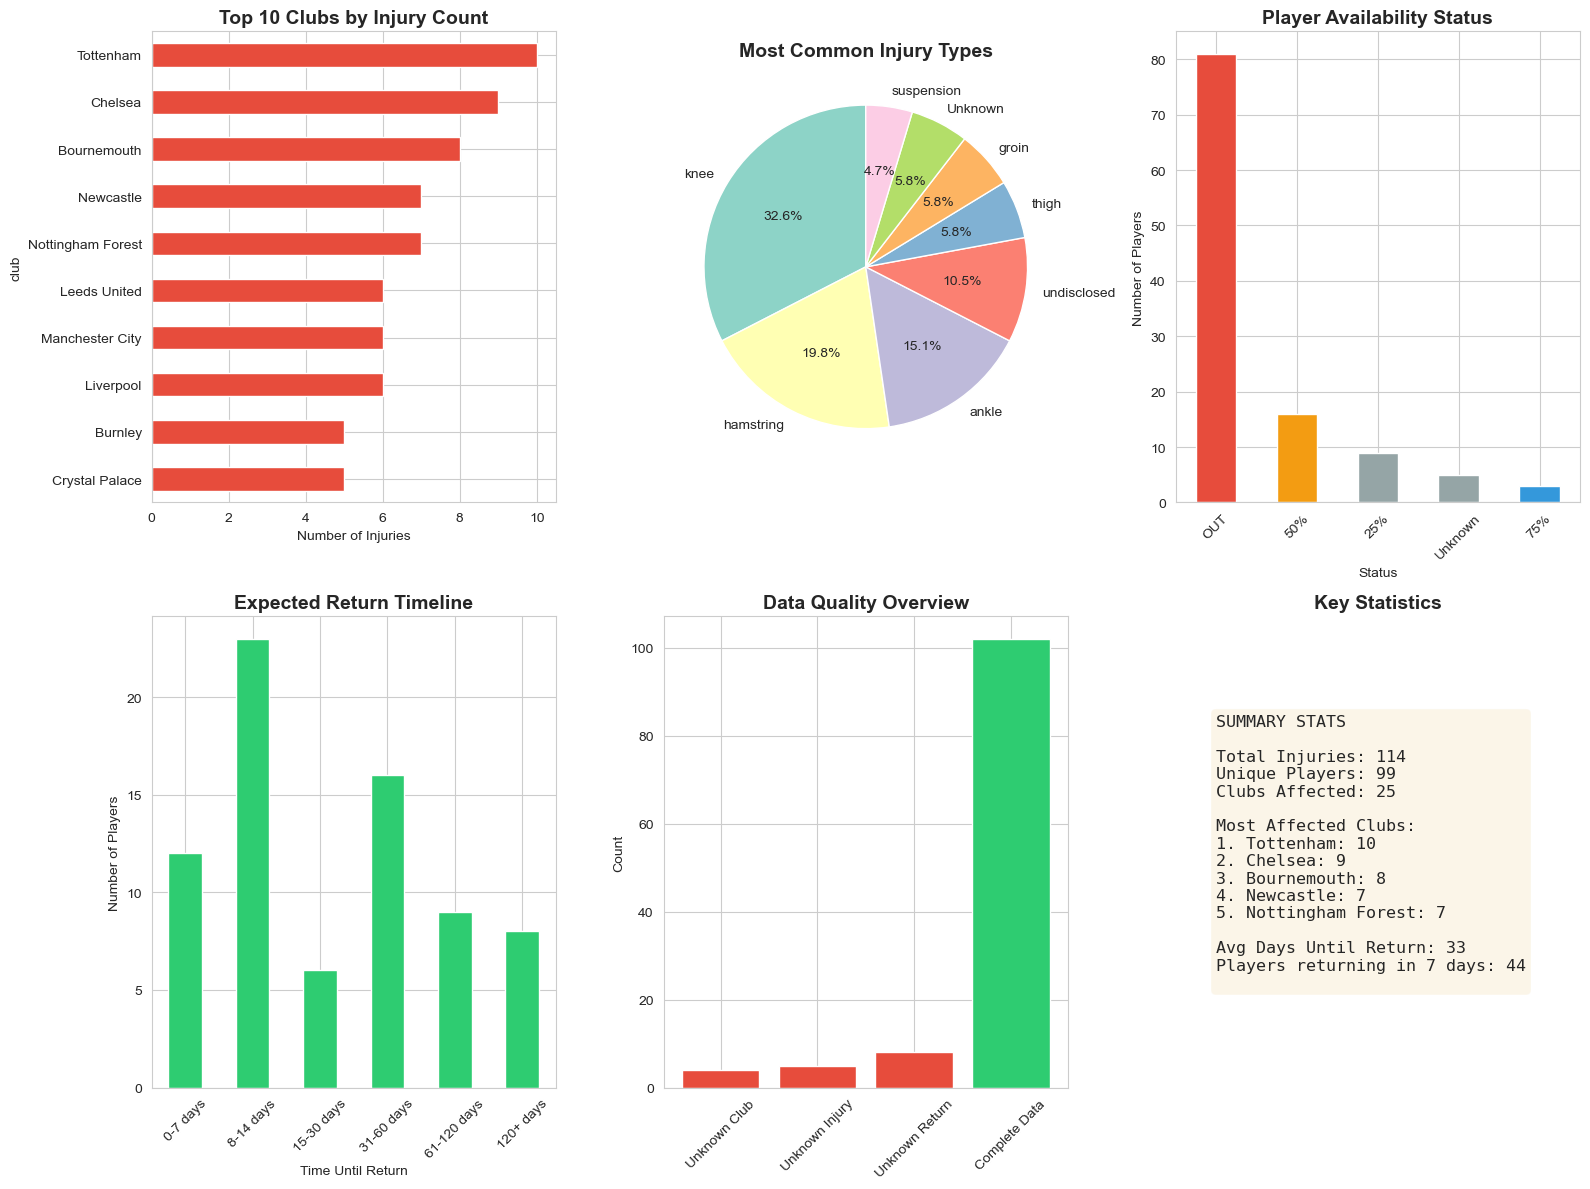

Dashboard displayed!


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 10)

# Create a figure with subplots
fig = plt.figure(figsize=(16, 12))

# 1. Top 10 Clubs by Injury Count
ax1 = plt.subplot(2, 3, 1)
top_clubs = df['club'].value_counts().head(10)
top_clubs.plot(kind='barh', color='#e74c3c', ax=ax1)
ax1.set_xlabel('Number of Injuries')
ax1.set_title('Top 10 Clubs by Injury Count', fontsize=14, fontweight='bold')
ax1.invert_yaxis()

# 2. Injury Type Distribution
ax2 = plt.subplot(2, 3, 2)
top_injuries = df['injury_type'].value_counts().head(8)
colors = plt.cm.Set3(range(len(top_injuries)))
ax2.pie(top_injuries.values, labels=top_injuries.index, autopct='%1.1f%%', 
        colors=colors, startangle=90)
ax2.set_title('Most Common Injury Types', fontsize=14, fontweight='bold')

# 3. Status Breakdown
ax3 = plt.subplot(2, 3, 3)
status_counts = df['status'].value_counts()
colors_status = {'OUT': '#e74c3c', '50%': '#f39c12', '75%': '#3498db', '25%': '#95a5a6'}
bar_colors = [colors_status.get(x, '#95a5a6') for x in status_counts.index]
status_counts.plot(kind='bar', color=bar_colors, ax=ax3)
ax3.set_xlabel('Status')
ax3.set_ylabel('Number of Players')
ax3.set_title('Player Availability Status', fontsize=14, fontweight='bold')
ax3.tick_params(axis='x', rotation=45)

# 4. Return Timeline Distribution
ax4 = plt.subplot(2, 3, 4)
df_temp = df[df['expected_return'] != 'Unknown'].copy()
if len(df_temp) > 0:
    df_temp['return_date'] = pd.to_datetime(df_temp['expected_return'], format='%d/%m/%y', errors='coerce')
    df_temp['days_until_return'] = (df_temp['return_date'] - pd.Timestamp.now()).dt.days
    
    bins = [0, 7, 14, 30, 60, 120, 365]
    labels = ['0-7 days', '8-14 days', '15-30 days', '31-60 days', '61-120 days', '120+ days']
    df_temp['return_category'] = pd.cut(df_temp['days_until_return'], bins=bins, labels=labels)
    
    return_dist = df_temp['return_category'].value_counts().sort_index()
    return_dist.plot(kind='bar', color='#2ecc71', ax=ax4)
    ax4.set_xlabel('Time Until Return')
    ax4.set_ylabel('Number of Players')
    ax4.set_title('Expected Return Timeline', fontsize=14, fontweight='bold')
    ax4.tick_params(axis='x', rotation=45)

# 5. Data Quality Overview
ax5 = plt.subplot(2, 3, 5)
unknown_data = {
    'Unknown Club': len(df[df['club'] == 'Unknown']),
    'Unknown Injury': len(df[df['injury_type'] == 'Unknown']),
    'Unknown Return': len(df[df['expected_return'] == 'Unknown']),
    'Complete Data': len(df[(df['club'] != 'Unknown') & 
                           (df['injury_type'] != 'Unknown') & 
                           (df['expected_return'] != 'Unknown')])
}
colors_quality = ['#e74c3c', '#e74c3c', '#e74c3c', '#2ecc71']
ax5.bar(unknown_data.keys(), unknown_data.values(), color=colors_quality)
ax5.set_ylabel('Count')
ax5.set_title('Data Quality Overview', fontsize=14, fontweight='bold')
ax5.tick_params(axis='x', rotation=45)

# 6. Summary Stats
ax6 = plt.subplot(2, 3, 6)
top_5_text = df['club'].value_counts().head(5)
ax6.axis('off')
text_str = "SUMMARY STATS\n\n"  # Removed emoji
text_str += f"Total Injuries: {len(df)}\n"
text_str += f"Unique Players: {df['player'].nunique()}\n"
text_str += f"Clubs Affected: {df['club'].nunique()}\n\n"
text_str += "Most Affected Clubs:\n"
for i, (club, count) in enumerate(top_5_text.items(), 1):
    text_str += f"{i}. {club}: {count}\n"

if len(df_temp) > 0:
    text_str += f"\nAvg Days Until Return: {df_temp['days_until_return'].mean():.0f}\n"
    text_str += f"Players returning in 7 days: {len(df_temp[df_temp['days_until_return'] <= 7])}\n"

ax6.text(0.1, 0.5, text_str, fontsize=12, verticalalignment='center',
         fontfamily='monospace', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
ax6.set_title('Key Statistics', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("Dashboard displayed!")